# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

# 0.2. Мої відповіді:

###1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
Якщо передати один суцільний рядок, BPE навчатиметься на об’єднаному тексті. На межах віршів можуть утворитися небажані токени, що поєднують кінець одного вірша з початком іншого. Сам алгоритм не зламається, але словник може відрізнятися. Цю ситуацію й уникаємо, використовуючи роздільники між віршами.

###2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))

Токенізація складається з чотирьох основних етапів:
1. Нормалізація (Normalization) — очищення тексту: наприклад, зміна регістру, видалення зайвих пробілів або діакритичних знаків.
2. Попереднє розбиття (Pre-tokenization) — поділ тексту на слова або інші початкові частини за пробілами та розділовими знаками.
3. Токенізація моделлю (Model) — розбиття частин тексту на токени за правилами алгоритму, наприклад BPE, та присвоєння їм ID зі словника.
4. Постобробка (Post-processing) — додавання спеціальних токенів, наприклад початку або кінця послідовності, якщо це передбачено налаштуваннями.

###3. Що таке `"<unk>", "<eos>"` в 2.1.?

`unk` (unknown) — спеціальний токен для позначення невідомого символу або фрагмента тексту, який токенізатор не може представити звичайними токенами.

`eos` (end of sequence) — спеціальний токен, що позначає кінець послідовності текст

###4. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000)...

При зменшенні словника з 16000 до 6000 токенів кількість токенів у корпусі зросла з 18 421 968 до 21 041 508, частка `unk` залишилася 0% в обох випадках.
Менший словник містить менше великих об'єднаних фрагментів, тому текст розбивається на більшу кількість дрібніших токенів. За незмінного CONTEXT_LEN модель оброблятиме менше тексту за один контекст, оскільки кожен токен відповідатиме меншому фрагменту тексту.

###5. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?

Токен `eos` позначає кінець кожного вірша та відокремлює його від наступного. Якщо прибрати цей токен, mini-GPT сприйматиме сусідні вірші як один суцільний текст і навчатиметься переходам між кінцем одного вірша та початком іншого.


###6. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?

train_data і val_data — це одновимірні тензори PyTorch типу int64, елементи яких є числовими ID токенів, отриманих після токенізації текстів.
Кожне число відповідає певному токену зі словника BPE. Модель навчається передбачати наступний токен на основі попередніх


###7. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
assert не виводить повідомлення, отже перевірка підтвердила, що `y` правильно зсунений відносно `x` на одну позицію.

`assert torch.equal(x[:, 1:], y[:, :-1]), "Помилка: токени не збігаються зі зсувом на 1!"`

###8. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
Нижньотрикутна маска використовується, щоб кожен токен міг враховувати лише попередні токени та себе, але не майбутні. Верхньотрикутна маска обмежила б доступ до попередніх токенів, що порушило б логіку генерації.

Якби маски не було, модель під час навчання могла б бачити майбутні токени й використовувати їх для передбачення наступних. Це призвело б до витоку інформації.


###9. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.

У моєму випадку val_loss поступово зменшувався протягом усього навчання й досягнув найменшого значення 5.651 на ітерації 7999. Отже, найкращий і останній чекпоінти збігаються. Хоча криві train_loss і val_loss дещо розходяться.

###10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?

Зменшення EVAL_INTERVAL з 250 до 50 зробило оцінювання моделі частішим, але крива не стала помітно плавнішою — навпаки, стала більш хвилястою, оскільки частіше відображаються коливання. Час тренування практично не збільшився: 6,5 хв проти 6,8 хв у попередньому запуску. Тому в цьому випадку частіше оцінювання було доцільним.

###11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
Температура впливає на ймовірність вибору наступного токена.
- Низька температура (0.2) робить модель більш передбачуваною: вона частіше вибирає найімовірніші токени, тому текст виходить послідовнішим, але менш різноманітним.
- Висока температура (1.4) робить імовірності токенів більш схожими, тому модель частіше вибирає менш очікувані слова, а текст може втрачати логічність.
Зі збільшенням температури текст стає різноманітнішим, але менш передбачуваним. За дуже високої температури вибір токенів наближається до випадкового.

###12. За що саме відповідає параметр `top_p`?
Параметр top_p визначає, які токени можуть бути обрані під час генерації тексту. Модель залишає найімовірніші токени, сумарна ймовірність яких досягає заданого значення top_p, а решту відкидає. Тобто він регулює різноманітність вибору наступного токена: чим він нижчий, тим більш передбачуваним зазвичай буде текст.

###13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.
При `enable_thinking=False` модель одразу генерує продовження історії. При `enable_thinking=True` вона спочатку виводить проміжні міркування у спеціальному блоці <think>, а вже потім має сформувати відповідь.

У цьому прикладі замість продовження оповідання модель вивела міркування англійською мовою, які містять повтори та неточності. Це показує, що режим thinking змінює формат генерації, але не гарантує кращої якості кінцевого тексту.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [1]:
!pip install "transformers[sentencepiece]==5.18.0"

In [16]:
import os

from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


In [3]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: Tesla T4


In [4]:
from datasets import load_dataset
import pandas as pd

# Завантажуємо лише українську вибірку
dataset = load_dataset(
    "agentlans/allenai-WildChat",
    "uk",
    split="train"
)

print("Кількість розмов:", len(dataset))
print("Колонки:", dataset.column_names)

# Витягуємо тільки відповіді асистента
texts = []

for row in dataset:
    for message in row["conversations"]:
        if message["from"] == "gpt":
            text = message["value"].strip()
            if text:
                texts.append(text)

# Створюємо DataFrame у форматі, сумісному з лабораторною
poems_df = pd.DataFrame({"context_poem": texts})

print("Кількість текстів:", len(poems_df))
print(
    "Загальна кількість символів:",
    poems_df["context_poem"].str.len().sum()
)
print("\nПриклад тексту:\n", poems_df["context_poem"].iloc[0])


Кількість розмов: 4432
Колонки: ['model', 'conversations', 'language', 'source']
Кількість текстів: 9741
Загальна кількість символів: 11255103

Приклад тексту:
 Косплей - це мистецтво та хобі, яке дозволяє фанам втілювати образи улюблених персонажів з фільмів, коміксів, мультсеріалів та інших медій. Якщо ви бажаєте створити точний косплей образу доктора Еллі Саттлер з фільму «Парк Юрського Періоду», ми підготували для вас кілька порад і рекомендацій.

1. Реквізит: Почніть з пошуку необхідних реквізитів для вашого косплею. Доктор Еллі Саттлер виступала у фільмі в легкому флористичному костюмі з довгими чорними волоссям та слюдяними срібними сережками.

2. Костюм: Ви можете купити готовий костюм доктора Еллі Саттлер або зробити його самостійно. Вам знадобиться бежева сорочка та штани, коричневий пояс, жилет, лісова або зелена куртка, книжка про рослини та ботаніка та високі чорні черевики.

3. Волосся та макіяж: Щоб відтворити образ доктора Саттлер, додайте чорний парік або підфарбуйте в

#1.2. Збираємо суцільний корпус

In [5]:
corpus_text = "\n\n".join(
    poems_df["context_poem"].dropna().tolist()
)

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])


Розмір корпусу: 11274583 символів
Перші 500 символів корпусу:
 Косплей - це мистецтво та хобі, яке дозволяє фанам втілювати образи улюблених персонажів з фільмів, коміксів, мультсеріалів та інших медій. Якщо ви бажаєте створити точний косплей образу доктора Еллі Саттлер з фільму «Парк Юрського Періоду», ми підготували для вас кілька порад і рекомендацій.

1. Реквізит: Почніть з пошуку необхідних реквізитів для вашого косплею. Доктор Еллі Саттлер виступала у фільмі в легкому флористичному костюмі з довгими чорними волоссям та слюдяними срібними сережками.

2


#1.3. Базова статистика корпусу

In [6]:
words = corpus_text.split()
unique_words = set(word.lower() for word in words)

print("Слів (з повторами):", len(words))
print("Унікальних слів:", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами): 1520295
Унікальних слів: 212684
Приклад уривку:

Косплей - це мистецтво та хобі, яке дозволяє фанам втілювати образи улюблених персонажів з фільмів, коміксів, мультсеріалів та інших медій. Якщо ви бажаєте створити точний косплей образу доктора Еллі Саттлер з фільму «Парк Юрського Періоду», ми підготували для вас кілька порад і рекомендацій.

1. Реквізит: Почніть з пошуку необхідних реквізитів для вашого косплею. Доктор Еллі Саттлер виступала у фільмі в легкому флористичному костюмі з довгими чорними волоссям та слюдяними срібними сережками.

2


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

#2.0 Підготовка даних
Задаємо спільні параметри для всіх трьох алгоритмів.

In [7]:
from collections import Counter
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 3500
SPECIAL_TOKENS = ["<unk>", "<eos>"]

# Беремо тексти з нашого датасету WildChat
texts = poems_df["context_poem"].dropna().tolist()
texts = [text.strip() for text in texts if text.strip()]

# Для порівняння використовуємо однаковий зразок для всіх алгоритмів
sample_texts = texts[:3500]

print("Усього текстів:", len(texts))
print("Текстів у зразку:", len(sample_texts))
print("Символів у зразку:", sum(len(text) for text in sample_texts))


Усього текстів: 9741
Текстів у зразку: 3500
Символів у зразку: 4161921


#2.1. Розминка: тренування на основі готового токенізатора

In [8]:
from transformers import AutoTokenizer

base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

custom_qwen_tokenizer = base_tokenizer.train_new_from_iterator(
    texts,
    vocab_size=VOCAB_SIZE
)

print("Розмір словника Qwen:", len(custom_qwen_tokenizer))
print(
    "Приклад токенізації:",
    custom_qwen_tokenizer.tokenize(sample_texts[0][:200])
)


Розмір словника Qwen: 3508
Приклад токенізації: ['Ðļ', 'Ð¾ÑģÐ¿', 'Ð»ÐµÐ¹', 'Ġ-', 'ĠÑĨÐµ', 'ĠÐ¼Ð¸ÑģÑĤÐµÑĨÑĤ', 'Ð²Ð¾', 'ĠÑĤÐ°', 'ĠÑħ', 'Ð¾Ð±Ñĸ', ',', 'ĠÑıÐºÐµ', 'ĠÐ´Ð¾Ð·Ð²Ð¾Ð»ÑıÑĶ', 'ĠÑĦ', 'Ð°Ð½', 'Ð°Ð¼', 'ĠÐ²ÑĤÑĸ', 'Ð»ÑİÐ²Ð°ÑĤÐ¸', 'ĠÐ¾Ð±ÑĢÐ°', 'Ð·Ð¸', 'ĠÑĥ', 'Ð»Ñİ', 'Ð±', 'Ð»ÐµÐ½Ð¸Ñħ', 'ĠÐ¿ÐµÑĢÑģÐ¾Ð½Ð°Ð¶ÑĸÐ²', 'ĠÐ·', 'ĠÑĦ', 'ÑĸÐ»ÑĮ', 'Ð¼ÑĸÐ²', ',', 'ĠÐºÐ¾Ð¼', 'ÑĸÐº', 'ÑģÑĸÐ²', ',', 'ĠÐ¼ÑĥÐ»ÑĮ', 'ÑĤ', 'ÑģÐµÑĢ', 'ÑĸÐ°', 'Ð»ÑĸÐ²', 'ĠÑĤÐ°', 'ĠÑĸÐ½ÑĪÐ¸Ñħ', 'ĠÐ¼', 'ÐµÐ´', 'ÑĸÐ¹', '.', 'ĠÐ¯ÐºÑīÐ¾', 'ĠÐ²Ð¸', 'ĠÐ±Ð°', 'Ð¶Ð°', 'ÑĶÑĤÐµ', 'ĠÑģÑĤÐ²Ð¾ÑĢÐ¸ÑĤÐ¸', 'ĠÑĤÐ¾', 'ÑĩÐ½Ð¸Ð¹', 'ĠÐº', 'Ð¾ÑģÐ¿', 'Ð»ÐµÐ¹', 'ĠÐ¾Ð±ÑĢÐ°', 'Ð·Ñĥ', 'ĠÐ´', 'Ð¾Ðº', 'ÑĤÐ¾ÑĢÐ°', 'ĠÐķ', 'Ð»', 'Ð»Ñĸ', 'Ġ']


#2.2. BPE

In [9]:
bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

bpe_tokenizer.train_from_iterator(
    texts,
    trainer=bpe_trainer
)

bpe_vocab = bpe_tokenizer.get_vocab()

print("Розмір словника BPE:", len(bpe_vocab))
print("Приклад:", bpe_tokenizer.encode(sample_texts[0][:200]).tokens)


Розмір словника BPE: 3500
Приклад: ['Ðļ', 'Ð¾ÑģÐ¿', 'Ð»ÐµÐ¹', 'Ġ-', 'ĠÑĨÐµ', 'ĠÐ¼Ð¸ÑģÑĤÐµÑĨÑĤ', 'Ð²Ð¾', 'ĠÑĤÐ°', 'ĠÑħ', 'Ð¾Ð±Ñĸ', ',', 'ĠÑıÐºÐµ', 'ĠÐ´Ð¾Ð·Ð²Ð¾Ð»ÑıÑĶ', 'ĠÑĦ', 'Ð°Ð½', 'Ð°Ð¼', 'ĠÐ²ÑĤÑĸ', 'Ð»ÑİÐ²Ð°ÑĤÐ¸', 'ĠÐ¾Ð±ÑĢÐ°', 'Ð·Ð¸', 'ĠÑĥ', 'Ð»Ñİ', 'Ð±', 'Ð»ÐµÐ½Ð¸Ñħ', 'ĠÐ¿ÐµÑĢÑģÐ¾Ð½Ð°Ð¶ÑĸÐ²', 'ĠÐ·', 'ĠÑĦ', 'ÑĸÐ»ÑĮ', 'Ð¼ÑĸÐ²', ',', 'ĠÐºÐ¾Ð¼', 'ÑĸÐº', 'ÑģÑĸÐ²', ',', 'ĠÐ¼ÑĥÐ»ÑĮ', 'ÑĤ', 'ÑģÐµÑĢ', 'ÑĸÐ°', 'Ð»ÑĸÐ²', 'ĠÑĤÐ°', 'ĠÑĸÐ½ÑĪÐ¸Ñħ', 'ĠÐ¼', 'ÐµÐ´', 'ÑĸÐ¹', '.', 'ĠÐ¯ÐºÑīÐ¾', 'ĠÐ²Ð¸', 'ĠÐ±Ð°', 'Ð¶Ð°', 'ÑĶÑĤÐµ', 'ĠÑģÑĤÐ²Ð¾ÑĢÐ¸ÑĤÐ¸', 'ĠÑĤÐ¾', 'ÑĩÐ½Ð¸Ð¹', 'ĠÐº', 'Ð¾ÑģÐ¿', 'Ð»ÐµÐ¹', 'ĠÐ¾Ð±ÑĢÐ°', 'Ð·Ñĥ', 'ĠÐ´', 'Ð¾Ðº', 'ÑĤÐ¾ÑĢÐ°', 'ĠÐķ', 'Ð»', 'Ð»Ñĸ', 'Ġ']


#2.3. WordPiece

In [10]:
wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token="<unk>")
)

wordpiece_tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wordpiece_tokenizer.decoder = decoders.WordPiece(prefix="##")

wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

wordpiece_tokenizer.train_from_iterator(
    texts,
    trainer=wordpiece_trainer
)

wordpiece_vocab = wordpiece_tokenizer.get_vocab()

print("Розмір словника WordPiece:", len(wordpiece_vocab))
print(
    "Приклад:",
    wordpiece_tokenizer.encode(sample_texts[0][:200]).tokens
)

Розмір словника WordPiece: 3500
Приклад: ['К', '##о', '##сп', '##ле', '##й', '-', 'ц', '##е', 'м', '##ист', '##е', '##ц', '##т', '##во', 'та', 'х', '##об', '##і', ',', 'як', '##е', 'до', '##з', '##во', '##ля', '##є', 'ф', '##ан', '##а', '##м', 'в', '##ті', '##лю', '##вати', 'об', '##ра', '##з', '##и', 'у', '##лю', '##б', '##ле', '##них', 'п', '##ер', '##с', '##она', '##ж', '##ів', 'з', 'ф', '##іль', '##мі', '##в', ',', 'к', '##ом', '##і', '##к', '##сі', '##в', ',', 'м', '##у', '##ль', '##т', '##с', '##ер', '##і', '##а', '##лі', '##в', 'та', 'ін', '##ши', '##х', 'м', '##е', '##ді', '##й', '.', 'Я', '##к', '##щ', '##о', 'ви', 'ба', '##ж', '##а', '##є', '##те', 'ст', '##вор', '##ит', '##и', 'т', '##о', '##ч', '##ний', 'к', '##о', '##сп', '##ле', '##й', 'об', '##ра', '##зу', 'до', '##к', '##то', '##ра', 'Е', '##л', '##лі']


#2.4. Unigram

In [11]:
unigram_tokenizer = Tokenizer(models.Unigram())

unigram_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)
unigram_tokenizer.decoder = decoders.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)

unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token="<unk>"
)

unigram_tokenizer.train_from_iterator(
    texts,
    trainer=unigram_trainer
)

unigram_vocab = unigram_tokenizer.get_vocab()

print("Розмір словника Unigram:", len(unigram_vocab))
print(
    "Приклад:",
    unigram_tokenizer.encode(sample_texts[0][:200]).tokens
)


Розмір словника Unigram: 3500
Приклад: ['▁Ко', 'с', 'п', 'ле', 'й', '▁-', '▁це', '▁мистецтв', 'о', '▁та', '▁хо', 'б', 'і', ',', '▁як', 'е', '▁дозволяє', '▁ф', 'ан', 'ам', '▁в', 'ті', 'лю', 'вати', '▁образ', 'и', '▁у', 'лю', 'б', 'ле', 'них', '▁персонаж', 'ів', '▁з', '▁ф', 'іль', 'м', 'ів,', '▁ком', 'і', 'кс', 'ів,', '▁', 'м', 'уль', 'т', 'сер', 'і', 'ал', 'ів', '▁та', '▁інших', '▁', 'ме', 'д', 'ій', '.', '▁Якщо', '▁ви', '▁', 'ба', 'ж', 'а', 'є', 'те', '▁створити', '▁точн', 'ий', '▁ко', 'с', 'п', 'ле', 'й', '▁образ', 'у', '▁до', 'к', 'тор', 'а', '▁', 'Е', 'л', 'лі', '▁']


#2.5. Порівняння токенізаторів

In [12]:
tokenizers_dict = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

results = []

for name, tokenizer in tokenizers_dict.items():
    token_count = sum(
        len(tokenizer.encode(text).ids)
        for text in sample_texts
    )

    results.append({
        "Алгоритм": name,
        "Розмір словника": len(tokenizer.get_vocab()),
        "Кількість токенів у зразку": token_count
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Алгоритм,Розмір словника,Кількість токенів у зразку
0,BPE,3500,1495068
1,WordPiece,3500,2344953
2,Unigram,3500,1764386


#2.6. Порівняння частотного та рідкісного слова

In [13]:
word_counts = Counter(
    word.lower()
    for text in sample_texts
    for word in text.split()
    if word.strip()
)

frequent_word = word_counts.most_common(1)[0][0]

rare_words = [
    word for word, count in word_counts.items()
    if count == 1 and len(word) >= 5
]

rare_word = rare_words[0] if rare_words else min(
    word_counts,
    key=word_counts.get
)

print("Частотне слово:", frequent_word)
print("Рідкісне слово:", rare_word)

for name, tokenizer in tokenizers_dict.items():
    frequent_tokens = tokenizer.encode(frequent_word).tokens
    rare_tokens = tokenizer.encode(rare_word).tokens

    print(f"\n{name}")
    print("Частотне слово:", frequent_tokens, "| Кількість:", len(frequent_tokens))
    print("Рідкісне слово:", rare_tokens, "| Кількість:", len(rare_tokens))


Частотне слово: та
Рідкісне слово: фанам

BPE
Частотне слово: ['ÑĤÐ°'] | Кількість: 1
Рідкісне слово: ['ÑĦ', 'Ð°Ð½', 'Ð°Ð¼'] | Кількість: 3

WordPiece
Частотне слово: ['та'] | Кількість: 1
Рідкісне слово: ['ф', '##ан', '##а', '##м'] | Кількість: 4

Unigram
Частотне слово: ['▁та'] | Кількість: 1
Рідкісне слово: ['▁ф', 'ан', 'ам'] | Кількість: 3


# Висновок

Було порівняно алгоритми BPE, WordPiece та Unigram із розміром словника 3500 токенів на українськомовних текстах WildChat. Найменшу кількість токенів отримав BPE — 1 495 068, далі Unigram — 1 764 386, а WordPiece — 2 344 953. На рідкісному слові «фанам» BPE та Unigram використали по 3 токени, а WordPiece — 4. Отже, на цьому корпусі BPE забезпечив найкоротші послідовності токенів.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

#3.1.2 Навчаємо новий токенізатор

In [14]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

GPT_VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

# Беремо всі тексти з українського датасету WildChat
texts = poems_df["context_poem"].dropna().tolist()
texts = [text.strip() for text in texts if text.strip()]

print("Кількість текстів:", len(texts))
print("Кількість символів:", sum(len(text) for text in texts))

# Створюємо новий BPE-токенізатор
gpt_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
gpt_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel()
gpt_tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=GPT_VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    min_frequency=2,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

gpt_tokenizer.train_from_iterator(texts, trainer=trainer)

print("Фактичний розмір словника:", gpt_tokenizer.get_vocab_size())
print("ID токена <eos>:", gpt_tokenizer.token_to_id("<eos>"))


Кількість текстів: 9741
Кількість символів: 11255103
Фактичний розмір словника: 16000
ID токена <eos>: 1


#Кодуємо весь корпус

In [15]:
import numpy as np

EOS_ID = gpt_tokenizer.token_to_id("<eos>")
assert EOS_ID is not None, "У токенізаторі немає <eos>"

encoded_docs = []

for text in texts:
    ids = gpt_tokenizer.encode(text).ids
    encoded_docs.extend(ids)
    encoded_docs.append(EOS_ID)

data = np.array(encoded_docs, dtype=np.int32)

print("Розмір словника:", gpt_tokenizer.get_vocab_size())
print("Кількість токенів у корпусі:", len(data))
print("Тип даних:", data.dtype)
print("Перші 30 ID:", data[:30])

Розмір словника: 16000
Кількість токенів у корпусі: 2960161
Тип даних: int32
Перші 30 ID: [  524  2340  1559   371   614  5969   317 15505    13  1885  1459   413
   293   728  3432  2498  5776  7009  2615  3334   284  3731  2286    13
   639  1167  1071    13  7287   749]


#3.1.3 Спліт train/val


In [16]:
# Розділяємо дані: 90% на навчання, 10% на валідацію
split_idx = int(len(data) * 0.9)

train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)

train: (2664144,)  val: (296017,)


#Гіперпараметри варіанта 1

In [17]:
import os
import time
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter

CONTEXT_LEN = 64
EMBED_DIM = 128
N_HEADS = 4
N_LAYERS = 4
DROPOUT = 0.1
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
MAX_ITERS = 8000
EVAL_INTERVAL = 250
EVAL_ITERS = 50

VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3/models"
RUNS_DIR = "/content/drive/MyDrive/ai_systems/lab3/runs"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Пристрій:", device)
print("Розмір словника:", VOCAB_SIZE)
print("Кількість train-токенів:", len(train_data))
print("Кількість val-токенів:", len(val_data))

Пристрій: cuda
Розмір словника: 16000
Кількість train-токенів: 2664144
Кількість val-токенів: 296017


#Отримання батчів

In [18]:
train_data = torch.as_tensor(train_data, dtype=torch.long)
val_data = torch.as_tensor(val_data, dtype=torch.long)

def get_batch(split: str):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - CONTEXT_LEN - 1,
        (BATCH_SIZE,)
    )

    x = torch.stack([
        source[i:i + CONTEXT_LEN] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    assert torch.equal(x[:, 1:], y[:, :-1]), \
        "Помилка: токени не збігаються зі зсувом на 1!"

    return x.to(device), y.to(device)


xb, yb = get_batch("train")

print("Форма батчу x:", xb.shape, " y:", yb.shape)

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])


#Архітектура моделі

In [19]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.register_buffer(
            "tril",
            torch.tril(torch.ones(context_len, context_len))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)

        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        v = self.value(x)
        out = wei @ v
        return out


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads

        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout)
            for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.sa = MultiHeadAttention(
            embed_dim, n_heads, context_len, dropout
        )
        self.ffwd = FeedForward(embed_dim, dropout)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        n_heads,
        n_layers,
        context_len,
        dropout,
    ):
        super().__init__()
        self.context_len = context_len

        self.token_embedding_table = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding_table = nn.Embedding(context_len, embed_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout)
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)

            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(
                    logits,
                    min(top_k, logits.shape[-1])
                )
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)

        return idx

#Ініціалізація моделі 1

In [20]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")

Кількість параметрів: 4,912,000


#Навчання та збереження minigpt_v1.pt

In [21]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}

    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)

        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()

        out[split] = losses.mean().item()

    model.train()
    return out


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v1")
)

BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v1.pt"
)

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60

        print(
            f"iter {it:5d}  "
            f"train_loss={losses['train']:.3f}  "
            f"val_loss={losses['val']:.3f}  "
            f"({elapsed_min:.1f} хв)"
        )

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save({
                "model_state_dict": model.state_dict(),
                "vocab_size": VOCAB_SIZE,
                "context_len": CONTEXT_LEN,
                "embed_dim": EMBED_DIM,
                "n_heads": N_HEADS,
                "n_layers": N_LAYERS,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_iter": best_iter,
            }, BEST_CKPT_PATH)

writer.close()

print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter} (val_loss={best_val_loss:.3f})")
print("Модель збережена:", BEST_CKPT_PATH)

iter     0  train_loss=9.800  val_loss=9.803  (0.0 хв)
iter   250  train_loss=7.750  val_loss=7.802  (0.2 хв)
iter   500  train_loss=7.314  val_loss=7.411  (0.4 хв)
iter   750  train_loss=6.936  val_loss=7.050  (0.6 хв)
iter  1000  train_loss=6.668  val_loss=6.809  (0.8 хв)
iter  1250  train_loss=6.438  val_loss=6.600  (1.0 хв)
iter  1500  train_loss=6.215  val_loss=6.427  (1.2 хв)
iter  1750  train_loss=6.049  val_loss=6.265  (1.4 хв)
iter  2000  train_loss=5.883  val_loss=6.126  (1.6 хв)
iter  2250  train_loss=5.743  val_loss=5.999  (1.8 хв)
iter  2500  train_loss=5.608  val_loss=5.892  (2.0 хв)
iter  2750  train_loss=5.462  val_loss=5.819  (2.2 хв)
iter  3000  train_loss=5.379  val_loss=5.741  (2.4 хв)
iter  3250  train_loss=5.301  val_loss=5.644  (2.6 хв)
iter  3500  train_loss=5.190  val_loss=5.587  (2.8 хв)
iter  3750  train_loss=5.136  val_loss=5.540  (3.1 хв)
iter  4000  train_loss=5.058  val_loss=5.474  (3.3 хв)
iter  4250  train_loss=4.976  val_loss=5.413  (3.5 хв)
iter  4500

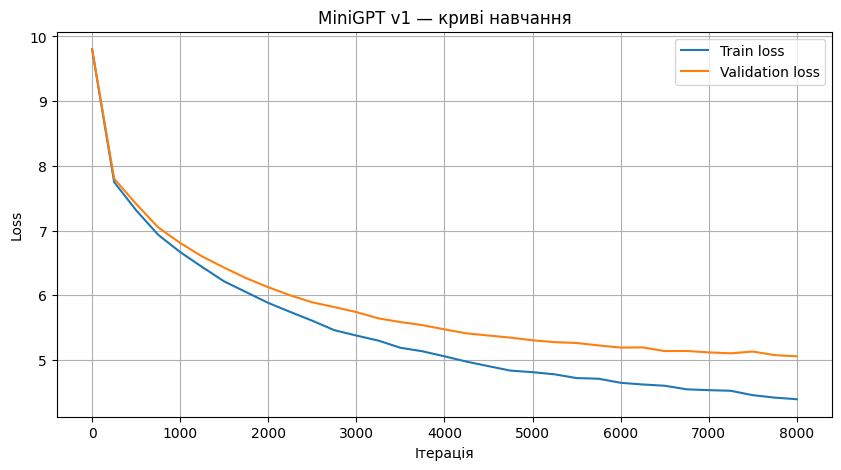

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("MiniGPT v1 — криві навчання")
plt.legend()
plt.grid(True)
plt.show()

#Параметри MiniGPT v2

In [23]:
# MiniGPT v2 — новий набір параметрів
CONTEXT_LEN = 128
EMBED_DIM = 192
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1

BATCH_SIZE = 64
LEARNING_RATE = 3e-4
MAX_ITERS = 8000
EVAL_INTERVAL = 250
EVAL_ITERS = 50

assert EMBED_DIM % N_HEADS == 0
HEAD_DIM = EMBED_DIM // N_HEADS

VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

print("Параметри MiniGPT v2:")
print(f"VOCAB_SIZE: {VOCAB_SIZE}")
print(f"CONTEXT_LEN: {CONTEXT_LEN}")
print(f"EMBED_DIM: {EMBED_DIM}")
print(f"N_HEADS: {N_HEADS}")
print(f"N_LAYERS: {N_LAYERS}")
print(f"BATCH_SIZE: {BATCH_SIZE}")
print(f"LEARNING_RATE: {LEARNING_RATE}")
print(f"MAX_ITERS: {MAX_ITERS}")

Параметри MiniGPT v2:
VOCAB_SIZE: 16000
CONTEXT_LEN: 128
EMBED_DIM: 192
N_HEADS: 4
N_LAYERS: 3
BATCH_SIZE: 64
LEARNING_RATE: 0.0003
MAX_ITERS: 8000


#Створення моделі v2

In [24]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())

print(f"Кількість параметрів MiniGPT v2: {n_params:,}")

Кількість параметрів MiniGPT v2: 7,517,824


#Навчання та збереження minigpt_v2.pt

In [26]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}

    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)

        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()

        out[split] = losses.mean().item()

    model.train()
    return out


# Оптимізатор
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Окремий TensorBoard для MiniGPT v2
writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v2")
)

# Файл для найкращого чекпоінта v2
BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v2.pt"
)

train_losses = []
val_losses = []
checkpoint_iters = []

best_val_loss = float("inf")
best_iter = None
start_time = time.time()

print("Початок навчання MiniGPT v2...")

for it in range(MAX_ITERS):
    # Навчальний крок
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # Оцінювання моделі
    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        # Запис у TensorBoard
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60

        print(
            f"iter {it:5d} "
            f"train_loss={losses['train']:.3f} "
            f"val_loss={losses['val']:.3f} "
            f"({elapsed_min:.1f} хв)"
        )

        # Збереження лише найкращого чекпоінта
        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "vocab_size": VOCAB_SIZE,
                    "context_len": CONTEXT_LEN,
                    "embed_dim": EMBED_DIM,
                    "n_heads": N_HEADS,
                    "n_layers": N_LAYERS,
                    "dropout": DROPOUT,
                    "best_val_loss": best_val_loss,
                    "best_iter": best_iter,
                },
                BEST_CKPT_PATH
            )

writer.close()

print("\nНавчання MiniGPT v2 завершено!")
print(f"Найкраща ітерація: {best_iter}")
print(f"Найкращий val_loss: {best_val_loss:.3f}")
print(f"Чекпоінт збережено: {BEST_CKPT_PATH}")

Початок навчання MiniGPT v2...
iter     0 train_loss=6.202 val_loss=6.402 (0.1 хв)
iter   250 train_loss=5.837 val_loss=6.090 (0.6 хв)
iter   500 train_loss=5.622 val_loss=5.897 (1.1 хв)
iter   750 train_loss=5.380 val_loss=5.750 (1.6 хв)
iter  1000 train_loss=5.220 val_loss=5.598 (2.2 хв)
iter  1250 train_loss=5.087 val_loss=5.520 (2.7 хв)
iter  1500 train_loss=4.926 val_loss=5.395 (3.2 хв)
iter  1750 train_loss=4.813 val_loss=5.360 (3.7 хв)
iter  2000 train_loss=4.758 val_loss=5.288 (4.2 хв)
iter  2250 train_loss=4.654 val_loss=5.231 (4.7 хв)
iter  2500 train_loss=4.589 val_loss=5.151 (5.2 хв)
iter  2750 train_loss=4.532 val_loss=5.146 (5.8 хв)
iter  3000 train_loss=4.457 val_loss=5.085 (6.3 хв)
iter  3250 train_loss=4.410 val_loss=5.051 (6.8 хв)
iter  3500 train_loss=4.336 val_loss=5.023 (7.3 хв)
iter  3750 train_loss=4.286 val_loss=4.991 (7.8 хв)
iter  4000 train_loss=4.236 val_loss=4.963 (8.3 хв)
iter  4250 train_loss=4.217 val_loss=4.935 (8.8 хв)
iter  4500 train_loss=4.126 val_l

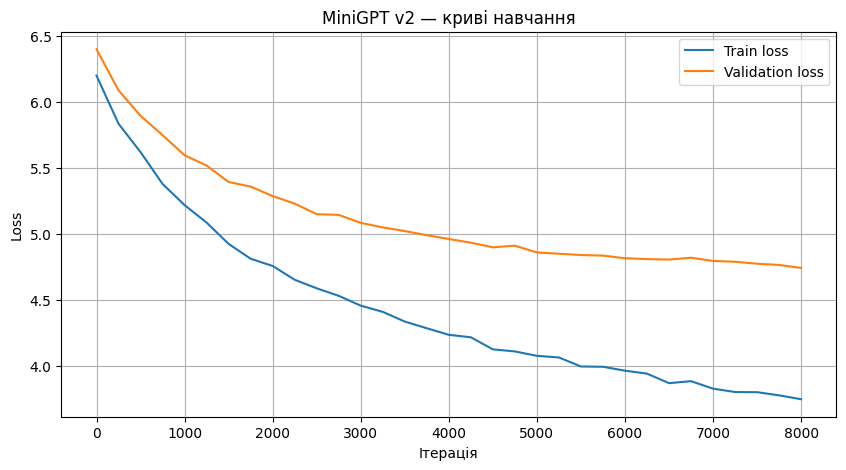

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("MiniGPT v2 — криві навчання")
plt.legend()
plt.grid(True)
plt.show()

#Генерація тексту - порівняня моделей

In [28]:
import os
import torch

# Шляхи до найкращих чекпоінтів
V1_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v1.pt")
V2_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2.pt")


def generate_text(
    checkpoint_path: str,
    prompt: str,
    max_new_tokens: int = 60,
    temperature: float = 0.8,
    top_k: int = 40,
) -> str:
    # Завантаження чекпоінта
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Створення моделі з параметрами саме цього чекпоінта
    model = MiniGPT(
        vocab_size=checkpoint["vocab_size"],
        embed_dim=checkpoint["embed_dim"],
        n_heads=checkpoint["n_heads"],
        n_layers=checkpoint["n_layers"],
        context_len=checkpoint["context_len"],
        dropout=checkpoint["dropout"],
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Токенізація промпту нашим BPE-токенізатором
    prompt_ids = torch.tensor(
        [gpt_tokenizer.encode(prompt).ids],
        dtype=torch.long,
        device=device
    )

    # Генерація продовження
    with torch.no_grad():
        output_ids = model.generate(
            prompt_ids,
            max_new_tokens=max_new_tokens,
            temperature=temperature,
            top_k=top_k
        )

    # Декодування токенів у текст
    return gpt_tokenizer.decode(output_ids[0].tolist())


# Однаковий промпт для обох моделей
PROMPT = "Привіт! Як справи?"

print("=== MiniGPT v1 ===")
print(generate_text(V1_CKPT_PATH, PROMPT))

print("\n" + "=" * 60 + "\n")

print("=== MiniGPT v2 ===")
print(generate_text(V2_CKPT_PATH, PROMPT))

=== MiniGPT v1 ===
 Привіт! Як справи? N На жаль, ви маєте у вашому запит або потрібна додаткова допомога, для будь ласка, будь ласка, уточніть, уточніть, можна сказати, але можу вам потрібно допомогти. Я, щоб з перекладом? Щоб виконати текст до запитання або з'являтися:

1. Якщо


=== MiniGPT v2 ===
 Привіт! Як справи? Дьяків Сава Федорович, I am sorry, but I do not possible to reconstructoring. He look like to do not just it. He not have repetary as if someone must have a hypothetical reconstruction during his voice.

1. What are the information or specific ancestors or any


#Висновки

Кращий результат показала **MiniGPT v2** з `val_loss = 4.785` проти 5.060 у v1. Її згенерований текст містив більше доречних фраз, проте обидві моделі мали проблеми зі зв'язністю.

Найбільший потенційний вплив мала зміна довжини контексту з 64 до 128 токенів. Також збільшено розмір embedding зі 128 до 192 та зменшено кількість Transformer-блоків із чотирьох до трьох. Словник залишився незмінним. Оскільки параметри змінювалися одночасно, визначити вплив кожної зміни окремо неможливо.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
#!pip install "transformers[sentencepiece]==5.18.0"

In [29]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [30]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [31]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "In this course, we will teach you how to make a simple web scraper using Python and BeautifulSoup. You will learn how to extract data from a web page, parse the HTML, and store it in a file or database.\n\n**Prerequisites**\n\n* Basic knowledge of Python programming\n* Basic understanding of HTML and CSS\n* Basic understanding of file and database management\n\n**Estimated Time**\n\n* 1-2 hours\n\n**Step 1: Install Required Libraries**\n\nTo make a web scraper, you'll need to install a few Python libraries. You can install them using pip, Python's package manager.\n\n```bash\npip install beautifulsoup4 requests pandas\n```\n\n**Step 2: Import Libraries**\n\nIn your Python script, import the required libraries.\n\n```python\nimport requests\nfrom bs4 import BeautifulSoup\nimport pandas as pd\n```\n\n**Step 3: Send a GET Request**\n\nTo scrape a web page, you need to send a GET request to the URL of the page. You can use the `requests` library to do this.\n\n```pytho

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to use React with React and React.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'}, {'generated_text': "In this course, we will teach you how to use Python, and how to use Python to make your own games.\n\n\n\n\nA few quick links to the course:\nThe first part of this course is just a few brief links to the course. This course is a bit of a jump to get started on Python; you can check out the details here .\nThe second part is a lot of questions about Python. There are a couple of thi

In [32]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [33]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [34]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [35]:
#1 Sentiment analysis
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment"
)

texts = [
    "Мені дуже сподобався цей фільм!",
    "Цей застосунок постійно зависає, жахливий досвід."
]

print(classifier(texts))

del classifier

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'positive', 'score': 0.9046149849891663}, {'label': 'negative', 'score': 0.9330933094024658}]


In [36]:
#2 Zero-shot classification
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

result = classifier(
    "Студенти вивчають програмування та створюють власні застосунки.",
    candidate_labels=[
        "освіта",
        "технології",
        "спорт",
        "політика"
    ]
)

print(result)

del classifier

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{'sequence': 'Студенти вивчають програмування та створюють власні застосунки.', 'labels': ['технології', 'освіта', 'політика', 'спорт'], 'scores': [0.8782534003257751, 0.11926563084125519, 0.001297393231652677, 0.0011835993500426412]}


In [37]:
#3 Text generation
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="malteos/gpt2-uk"
)

result = generator(
    "Українські розробники створюють нову комп'ютерну гру, у якій",
    max_new_tokens=50,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.8,
    top_k=40,
    pad_token_id=generator.tokenizer.eos_token_id
)

for i, item in enumerate(result, 1):
    print(f"\nВаріант {i}:")
    print(item["generated_text"])

del generator

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'top_k', 'do_sample', 'temperature', 'pad_token_id', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Варіант 1:
Українські розробники створюють нову комп'ютерну гру, у якій за допомогою спеціального меню можна створити свій власний комп'ютер.Про цю статтю, яка раніше називалася «соціальних організацій», я вже розповідав, як вона потрапляє у поле зору журналістів.
Дописувачі мають надати будь-яку інформацію про діяльність організації, її діяльність,

Варіант 2:
Українські розробники створюють нову комп'ютерну гру, у якій можуть грати не тільки дорослі діти, а й дорослі.
Ігровий процес має свої особливості. У грі є два окремих розділи, де гравець може вибрати одну гру, що відповідає певному сюжету. Одна гра називається "Drake", друга — "Sat


In [38]:
#Fill-mask

from transformers import pipeline

unmasker = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base"
)

result = unmasker(
    "Омлет роблять з молока та <mask>.",
    top_k=5
)

for item in result:
    print(item["token_str"], "—", round(item["score"], 4))

del unmasker

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


води — 0.3255
цукру — 0.2518
яйця — 0.147
масла — 0.0563
риби — 0.0413


In [39]:
#Named Entity Recognition
from transformers import pipeline

ner = pipeline(
    "ner",
    model="ukr-models/uk-ner",
    aggregation_strategy="simple"
)

text = (
    "Тарас Шевченко народився в Україні, "
    "а Київ є столицею держави."
)

for entity in ner(text):
    print(entity)

del ner

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'entity_group': 'PER', 'score': np.float32(0.9999659), 'word': 'Тарас Шевченко', 'start': 0, 'end': 14}
{'entity_group': 'LOC', 'score': np.float32(0.99998236), 'word': 'Україні', 'start': 27, 'end': 34}
{'entity_group': 'LOC', 'score': np.float32(0.9999788), 'word': 'Київ', 'start': 38, 'end': 42}


In [40]:
#6 Table question answering
from transformers import pipeline

question_answerer = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq"
)

table = {
    "Місто": ["Київ", "Львів", "Одеса"],
    "Населення, млн": ["3.0", "0.7", "1.0"],
    "Область": [
        "Київська",
        "Львівська",
        "Одеська"
    ]
}

result = question_answerer(
    query="Яке населення Львова?",
    table=table
)

print(result)

del question_answerer

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'AVERAGE > Київ', 'coordinates': [(0, 0)], 'cells': ['Київ'], 'aggregator': 'AVERAGE'}


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

#Порівняйте моделі

##Дані для zero-shot classification

In [1]:
texts = [
    "Студенти складають іспити в університеті.",
    "Учитель пояснив нову тему учням.",
    "Школа відкрила сучасну наукову лабораторію.",
    "Університет запровадив нову освітню програму.",
    "Учні готуються до олімпіади з математики.",

    "Розробники випустили нову версію операційної системи.",
    "Штучний інтелект допомагає аналізувати великі обсяги даних.",
    "Компанія представила новий смартфон.",
    "Програмісти виправили помилки у вебзастосунку.",
    "Науковці створили ефективніший комп'ютерний процесор.",

    "Футбольна команда перемогла у фіналі чемпіонату.",
    "Спортсмен встановив новий світовий рекорд.",
    "Збірна готується до міжнародного турніру.",
    "Тренер оголосив склад команди на наступний матч.",
    "Баскетболісти здобули перемогу в останній секунді.",

    "Парламент розглядає новий законопроєкт.",
    "Уряд оголосив про зміни в державній політиці.",
    "Кандидати розпочали передвиборчу кампанію.",
    "Міністри зустрілися для обговорення міжнародних відносин.",
    "Виборці голосують на парламентських виборах."
]

references = (
    ["освіта"] * 5
    + ["технології"] * 5
    + ["спорт"] * 5
    + ["політика"] * 5
)

candidate_labels = [
    "освіта",
    "технології",
    "спорт",
    "політика"
]

##Порівняння двох моделей

In [2]:
%pip install -q transformers evaluate

#Перша модель — mDeBERTa

In [17]:
import os
import gc
import time
import torch
import pandas as pd
from transformers import pipeline

# Використовуємо ARTIFACT_DIR з початкової комірки
MODEL_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "mDeBERTa.pt")
RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")

model_name = "mDeBERTa"
model_id = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"

# Перевіряємо підготовлені дані
assert len(texts) == len(references), \
    "Кількість речень і правильних міток не збігається."
assert len(texts) > 0, "Список речень порожній."
assert len(candidate_labels) > 0, "Список міток порожній."

device_id = 0 if torch.cuda.is_available() else -1

# 1. Завантажуємо тільки mDeBERTa
classifier = pipeline(
    "zero-shot-classification",
    model=model_id,
    device=device_id
)

model = classifier.model
model.eval()

# 2. Рахуємо параметри
params = sum(p.numel() for p in model.parameters())

# 3. Тестуємо модель
if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = classifier(
    texts,
    candidate_labels=candidate_labels,
    batch_size=4
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

predictions = [output["labels"][0] for output in outputs]
scores = [float(output["scores"][0]) for output in outputs]

# 4. Обчислюємо Accuracy
accuracy = sum(
    pred == ref
    for pred, ref in zip(predictions, references)
) / len(references)

result_mdeberta = {
    "Модель": model_name,
    "Задача": "zero-shot-classification",
    "Accuracy": round(accuracy, 3),
    "Час, с": round(elapsed, 3),
    "Час на речення, с": round(elapsed / len(texts), 4),
    "Параметри, млн": round(params / 1_000_000, 2)
}

print("Загальні результати:")
display(pd.DataFrame([result_mdeberta]))

# 5. Зберігаємо ваги моделі та результати в .pt
torch.save(
    {
        "model_name": model_name,
        "model_id": model_id,
        "state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "predictions": predictions,
        "scores": scores,
        "references": list(references),
        "texts": list(texts),
        "candidate_labels": list(candidate_labels),
        "metrics": result_mdeberta
    },
    MODEL_PATH
)

assert os.path.isfile(MODEL_PATH), "Файл моделі не створено!"

print(f"Модель збережено: {MODEL_PATH}")
print(f"Розмір: {os.path.getsize(MODEL_PATH) / (1024**2):.2f} MB")

# 6. Формуємо результати для спільного results.csv
predictions_df = pd.DataFrame({
    "Тип тесту": ["zero-shot-classification"] * len(texts),
    "Модель": [model_name] * len(texts),
    "Речення": texts,
    "Правильна мітка": references,
    "Передбачення": predictions,
    "Оцінка": scores,
    "Accuracy": [result_mdeberta["Accuracy"]] * len(texts),
    "Час, с": [result_mdeberta["Час, с"]] * len(texts),
    "Час на речення, с": [
        result_mdeberta["Час на речення, с"]
    ] * len(texts),
    "Параметри, млн": [
        result_mdeberta["Параметри, млн"]
    ] * len(texts)
})

# Дописуємо в кінець, не перезаписуючи попередні результати
predictions_df.to_csv(
    RESULTS_PATH,
    mode="a",
    header=not os.path.exists(RESULTS_PATH),
    index=False,
    encoding="utf-8-sig"
)

assert os.path.isfile(RESULTS_PATH), "Файл results.csv не створено!"

print(f"Результати додано: {RESULTS_PATH}")
display(predictions_df)

# 7. Очищаємо пам'ять
del classifier, model, outputs
del predictions, scores, predictions_df

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("mDeBERTa видалена з оперативної пам'яті.")
print("Обидва файли збережено.")


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Загальні результати:


,Модель,Задача,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,mDeBERTa,zero-shot-classification,0.9,124.647,6.2324,278.81


Модель збережено: /content/drive/MyDrive/ai_systems/lab3/models/mDeBERTa.pt
Розмір: 531.86 MB
Результати додано: /content/drive/MyDrive/ai_systems/lab3/results.csv


,Тип тесту,Модель,Речення,Правильна мітка,Передбачення,Оцінка,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,zero-shot-classification,mDeBERTa,Студенти складають іспити в університеті.,освіта,освіта,0.804253,0.9,124.647,6.2324,278.81
1,zero-shot-classification,mDeBERTa,Учитель пояснив нову тему учням.,освіта,освіта,0.328487,0.9,124.647,6.2324,278.81
2,zero-shot-classification,mDeBERTa,Школа відкрила сучасну наукову лабораторію.,освіта,освіта,0.977897,0.9,124.647,6.2324,278.81
3,zero-shot-classification,mDeBERTa,Університет запровадив нову освітню програму.,освіта,освіта,0.996072,0.9,124.647,6.2324,278.81
4,zero-shot-classification,mDeBERTa,Учні готуються до олімпіади з математики.,освіта,освіта,0.955673,0.9,124.647,6.2324,278.81
5,zero-shot-classification,mDeBERTa,Розробники випустили нову версію операційної с...,технології,технології,0.793206,0.9,124.647,6.2324,278.81
6,zero-shot-classification,mDeBERTa,Штучний інтелект допомагає аналізувати великі ...,технології,освіта,0.438769,0.9,124.647,6.2324,278.81
7,zero-shot-classification,mDeBERTa,Компанія представила новий смартфон.,технології,технології,0.883024,0.9,124.647,6.2324,278.81
8,zero-shot-classification,mDeBERTa,Програмісти виправили помилки у вебзастосунку.,технології,технології,0.870504,0.9,124.647,6.2324,278.81
9,zero-shot-classification,mDeBERTa,Науковці створили ефективніший комп'ютерний пр...,технології,технології,0.778652,0.9,124.647,6.2324,278.81


mDeBERTa видалена з оперативної пам'яті.
Обидва файли збережено.


##Друга модель — XLM-RoBERTa

In [18]:
import os
import gc
import time
import torch
import pandas as pd
from transformers import pipeline

# Використовуємо ARTIFACT_DIR з початкової комірки
MODEL_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "XLM-RoBERTa.pt")
RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")

model_name = "XLM-RoBERTa"
model_id = "joeddav/xlm-roberta-large-xnli"

# Перевіряємо підготовлені дані
assert len(texts) == len(references), \
    "Кількість речень і правильних міток не збігається."
assert len(texts) > 0, "Список речень порожній."
assert len(candidate_labels) > 0, "Список міток порожній."

device_id = 0 if torch.cuda.is_available() else -1

# 1. Завантажуємо тільки XLM-RoBERTa
classifier = pipeline(
    "zero-shot-classification",
    model=model_id,
    device=device_id
)

model = classifier.model
model.eval()

# 2. Рахуємо параметри
params = sum(p.numel() for p in model.parameters())

# 3. Тестуємо модель
if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = classifier(
    texts,
    candidate_labels=candidate_labels,
    batch_size=4
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

predictions = [output["labels"][0] for output in outputs]
scores = [float(output["scores"][0]) for output in outputs]

# 4. Обчислюємо Accuracy
accuracy = sum(
    pred == ref
    for pred, ref in zip(predictions, references)
) / len(references)

result_xlm = {
    "Модель": model_name,
    "Задача": "zero-shot-classification",
    "Accuracy": round(accuracy, 3),
    "Час, с": round(elapsed, 3),
    "Час на речення, с": round(elapsed / len(texts), 4),
    "Параметри, млн": round(params / 1_000_000, 2)
}

print("Загальні результати:")
display(pd.DataFrame([result_xlm]))

# 5. Зберігаємо ваги моделі та результати в .pt
torch.save(
    {
        "model_name": model_name,
        "model_id": model_id,
        "state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "predictions": predictions,
        "scores": scores,
        "references": list(references),
        "texts": list(texts),
        "candidate_labels": list(candidate_labels),
        "metrics": result_xlm
    },
    MODEL_PATH
)

assert os.path.isfile(MODEL_PATH), \
    "Файл моделі не створено!"

print(f"Модель збережено: {MODEL_PATH}")
print(f"Розмір: {os.path.getsize(MODEL_PATH) / (1024**2):.2f} MB")

# 6. Формуємо результати для спільного results.csv
predictions_df = pd.DataFrame({
    "Тип тесту": ["zero-shot-classification"] * len(texts),
    "Модель": [model_name] * len(texts),
    "Речення": texts,
    "Правильна мітка": references,
    "Передбачення": predictions,
    "Оцінка": scores,
    "Accuracy": [result_xlm["Accuracy"]] * len(texts),
    "Час, с": [result_xlm["Час, с"]] * len(texts),
    "Час на речення, с": [
        result_xlm["Час на речення, с"]
    ] * len(texts),
    "Параметри, млн": [
        result_xlm["Параметри, млн"]
    ] * len(texts)
})

# Дописуємо в кінець, не перезаписуючи попередні результати
predictions_df.to_csv(
    RESULTS_PATH,
    mode="a",
    header=not os.path.exists(RESULTS_PATH),
    index=False,
    encoding="utf-8-sig"
)

assert os.path.isfile(RESULTS_PATH), \
    "Файл results.csv не створено!"

print(f"Результати додано: {RESULTS_PATH}")
display(predictions_df)

# 7. Очищаємо пам'ять
del classifier, model, outputs
del predictions, scores, predictions_df

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("XLM-RoBERTa видалена з оперативної пам'яті.")
print("Обидва файли збережено.")

config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Загальні результати:


,Модель,Задача,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,XLM-RoBERTa,zero-shot-classification,0.95,26.987,1.3493,559.89


Модель збережено: /content/drive/MyDrive/ai_systems/lab3/models/XLM-RoBERTa.pt
Розмір: 2135.95 MB
Результати додано: /content/drive/MyDrive/ai_systems/lab3/results.csv


,Тип тесту,Модель,Речення,Правильна мітка,Передбачення,Оцінка,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,zero-shot-classification,XLM-RoBERTa,Студенти складають іспити в університеті.,освіта,освіта,0.975457,0.95,26.987,1.3493,559.89
1,zero-shot-classification,XLM-RoBERTa,Учитель пояснив нову тему учням.,освіта,освіта,0.957122,0.95,26.987,1.3493,559.89
2,zero-shot-classification,XLM-RoBERTa,Школа відкрила сучасну наукову лабораторію.,освіта,освіта,0.597918,0.95,26.987,1.3493,559.89
3,zero-shot-classification,XLM-RoBERTa,Університет запровадив нову освітню програму.,освіта,освіта,0.961502,0.95,26.987,1.3493,559.89
4,zero-shot-classification,XLM-RoBERTa,Учні готуються до олімпіади з математики.,освіта,освіта,0.582112,0.95,26.987,1.3493,559.89
5,zero-shot-classification,XLM-RoBERTa,Розробники випустили нову версію операційної с...,технології,технології,0.871731,0.95,26.987,1.3493,559.89
6,zero-shot-classification,XLM-RoBERTa,Штучний інтелект допомагає аналізувати великі ...,технології,технології,0.849440,0.95,26.987,1.3493,559.89
7,zero-shot-classification,XLM-RoBERTa,Компанія представила новий смартфон.,технології,технології,0.768773,0.95,26.987,1.3493,559.89
8,zero-shot-classification,XLM-RoBERTa,Програмісти виправили помилки у вебзастосунку.,технології,технології,0.990966,0.95,26.987,1.3493,559.89
9,zero-shot-classification,XLM-RoBERTa,Науковці створили ефективніший комп'ютерний пр...,технології,технології,0.974768,0.95,26.987,1.3493,559.89


XLM-RoBERTa видалена з оперативної пам'яті.
Обидва файли збережено.


За результатами тестування кращою виявилася модель XLM-RoBERTa. Вона правильно класифікувала всі наведені 10 речень і виконала завдання приблизно у 4,6 раза швидше за mDeBERTa. Попри більшу кількість параметрів, XLM-RoBERTa продемонструвала кращі результати, тому є доцільнішим вибором для цієї задачі.

#Експерименти: зміна порогу впевненості

In [20]:
import os
import gc
import time
import torch
import pandas as pd
from transformers import pipeline

MODEL_DIR = os.path.join(ARTIFACT_DIR, "models")
RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")
os.makedirs(MODEL_DIR, exist_ok=True)

model_name = "XLM-RoBERTa"
model_id = "joeddav/xlm-roberta-large-xnli"

# Три експерименти: змінюємо тільки поріг впевненості
thresholds = [0.60, 0.75, 0.90]

assert len(texts) == len(references) and len(texts) > 0
assert len(candidate_labels) > 0

device_id = 0 if torch.cuda.is_available() else -1

# 1. Завантажуємо модель та виконуємо класифікацію
classifier = pipeline(
    "zero-shot-classification",
    model=model_id,
    device=device_id
)

model = classifier.model
model.eval()

params = sum(p.numel() for p in model.parameters())

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = classifier(
    texts,
    candidate_labels=candidate_labels,
    batch_size=4
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

# Початкові передбачення не змінюються між експериментами
predictions = [out["labels"][0] for out in outputs]
scores = [float(out["scores"][0]) for out in outputs]

# Базова точність без порога
baseline_accuracy = sum(
    p == r for p, r in zip(predictions, references)
) / len(references)

print(f"Початкова Accuracy: {baseline_accuracy:.3f}")
print(f"Час класифікації: {elapsed:.3f} с")

# 2. Проводимо три експерименти
experiment_results = []

for threshold in thresholds:
    # Приймаємо передбачення, якщо оцінка >= порога
    accepted = [score >= threshold for score in scores]

    accepted_count = sum(accepted)
    coverage = accepted_count / len(texts)

    correct_accepted = sum(
        pred == ref
        for pred, ref, is_accepted
        in zip(predictions, references, accepted)
        if is_accepted
    )

    accepted_accuracy = (
        correct_accepted / accepted_count
        if accepted_count > 0
        else 0.0
    )

    result = {
        "Модель": model_name,
        "Параметр": "threshold",
        "Поріг": threshold,
        "Accuracy прийнятих": round(accepted_accuracy, 3),
        "Покриття, %": round(coverage * 100, 1),
        "Прийнято": accepted_count,
        "Усього": len(texts),
        "Початкова Accuracy": round(baseline_accuracy, 3),
        "Час, с": round(elapsed, 3),
        "Параметри, млн": round(params / 1_000_000, 2)
    }

    experiment_results.append(result)

    # 3. Зберігаємо окремий .pt для кожного порога
    model_path = os.path.join(
        MODEL_DIR,
        f"XLM-RoBERTa_threshold_{threshold:.2f}.pt"
    )

    torch.save(
        {
            "model_name": model_name,
            "model_id": model_id,
            "parameter": "threshold",
            "threshold": threshold,
            "state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "predictions": predictions,
            "scores": scores,
            "accepted": accepted,
            "references": list(references),
            "texts": list(texts),
            "candidate_labels": list(candidate_labels),
            "metrics": result
        },
        model_path
    )

    assert os.path.isfile(model_path), \
        f"Файл не створено: {model_path}"

    print(
        f"Збережено: {model_path} "
        f"({os.path.getsize(model_path) / (1024**2):.2f} MB)"
    )

    # 4. Дописуємо результати в спільний results.csv
    # Зберігаємо ту саму структуру колонок, що й раніше.
    predictions_df = pd.DataFrame({
        "Тип тесту": [
            f"zero-shot-classification; threshold={threshold:.2f}"
        ] * len(texts),
        "Модель": [model_name] * len(texts),
        "Речення": list(texts),
        "Правильна мітка": list(references),
        "Передбачення": [
            pred if is_accepted else f"ВІДХИЛЕНО: {pred}"
            for pred, is_accepted in zip(predictions, accepted)
        ],
        "Оцінка": scores,
        "Accuracy": [round(accepted_accuracy, 3)] * len(texts),
        "Час, с": [round(elapsed, 3)] * len(texts),
        "Час на речення, с": [
            round(elapsed / len(texts), 4)
        ] * len(texts),
        "Параметри, млн": [
            round(params / 1_000_000, 2)
        ] * len(texts)
    })

    predictions_df.to_csv(
        RESULTS_PATH,
        mode="a",
        header=not os.path.exists(RESULTS_PATH),
        index=False,
        encoding="utf-8-sig"
    )

# 5. Показуємо порівняльну таблицю
summary_df = pd.DataFrame(experiment_results)

print("\nПорівняння експериментів:")
display(summary_df)

print(f"Результати дописано до: {RESULTS_PATH}")

# 6. Очищаємо пам'ять
del classifier, model, outputs
del predictions, scores, predictions_df

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("XLM-RoBERTa видалена з оперативної пам'яті.")


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Початкова Accuracy: 0.950
Час класифікації: 64.467 с
Збережено: /content/drive/MyDrive/ai_systems/lab3/models/XLM-RoBERTa_threshold_0.60.pt (2135.96 MB)
Збережено: /content/drive/MyDrive/ai_systems/lab3/models/XLM-RoBERTa_threshold_0.75.pt (2135.96 MB)
Збережено: /content/drive/MyDrive/ai_systems/lab3/models/XLM-RoBERTa_threshold_0.90.pt (2135.96 MB)

Порівняння експериментів:


,Модель,Параметр,Поріг,Accuracy прийнятих,"Покриття, %",Прийнято,Усього,Початкова Accuracy,"Час, с","Параметри, млн"
0,XLM-RoBERTa,threshold,0.60,1.0,75.0,15,20,0.95,64.467,559.89
1,XLM-RoBERTa,threshold,0.75,1.0,75.0,15,20,0.95,64.467,559.89
2,XLM-RoBERTa,threshold,0.90,1.0,55.0,11,20,0.95,64.467,559.89


Результати дописано до: /content/drive/MyDrive/ai_systems/lab3/results.csv
XLM-RoBERTa видалена з оперативної пам'яті.


Під час експерименту з моделлю XLM-RoBERTa найкращі результати за точністю прийнятих передбачень показали всі три пороги — 0.60, 0.75 і 0.90, з Accuracy = 1.0. Однак при порозі 0.90 покриття знизилося з 75% до 55%: модель прийняла лише 11 із 20 передбачень замість 15. Отже, поріг 0.75 є доцільнішим компромісом, оскільки забезпечує максимальну точність серед прийнятих передбачень і більше покриття, ніж поріг 0.90.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [22]:
!pip -q install gradio transformers sentencepiece

import re
import torch
import pandas as pd
import gradio as gr
from transformers import pipeline

# Модель, яку ми вже тестували
MODEL_ID = "joeddav/xlm-roberta-large-xnli"

device_id = 0 if torch.cuda.is_available() else -1

classifier = pipeline(
    "zero-shot-classification",
    model=MODEL_ID,
    device=device_id
)

# Категорії товарів. За потреби можна розширювати.
CATEGORIES = [
    "маска для волосся",
    "шампунь для волосся",
    "кондиціонер для волосся",
    "спрей для волосся",
    "олія для волосся",
    "фарба для волосся",
    "крем для волосся",
    "гель для волосся",
    "мус для волосся",
    "засіб для укладання волосся",
    "інший засіб для волосся"
]

# Словник відомих брендів.
# Додавай сюди бренди, які зустрічаються у твоєму каталозі.
BRANDS = [
    "Shot",
    # "L'Oréal Professionnel",
    # "Wella Professionals",
    # "Schwarzkopf Professional",
]

def extract_volume(text):
    """Витягує об'єм або масу з назви."""
    match = re.search(
        r'(?<!\w)(\d+(?:[.,]\d+)?)\s*(мл|ml|літрів|літра|л|l|г|гр|g|кг|kg)\b',
        text,
        re.IGNORECASE
    )

    if not match:
        return ""

    value = match.group(1).replace(",", ".")
    unit = match.group(2).lower()

    units = {
        "ml": "мл",
        "мл": "мл",
        "літрів": "л",
        "літра": "л",
        "л": "л",
        "l": "л",
        "г": "г",
        "гр": "г",
        "g": "г",
        "кг": "кг",
        "kg": "кг"
    }

    return f"{value} {units[unit]}"


def extract_brand_and_line(text):
    """Визначає бренд за словником і текст після нього."""
    for brand in sorted(BRANDS, key=len, reverse=True):
        match = re.search(
            re.escape(brand),
            text,
            re.IGNORECASE
        )

        if match:
            brand_found = text[match.start():match.end()]
            tail = text[match.end():]

            # Відкидаємо об'єм і все після нього
            tail = re.split(
                r',?\s*\d+(?:[.,]\d+)?\s*'
                r'(?:мл|ml|л|l|г|гр|g|кг|kg)\b',
                tail,
                flags=re.IGNORECASE
            )[0]

            line = tail.strip(" ,–-")

            return brand_found, line

    return "", ""


def detect_product_type(text):
    """Класифікує товар за назвою."""
    result = classifier(
        text,
        candidate_labels=CATEGORIES,
        hypothesis_template="Цей товар належить до категорії {}."
    )

    return result["labels"][0], float(result["scores"][0])


def analyze_products(input_text):
    if not input_text or not input_text.strip():
        return pd.DataFrame(
            columns=[
                "Назва товару", "Категорія", "Бренд",
                "Лінійка", "Об'єм / маса", "Впевненість"
            ]
        )

    rows = []

    # Кожен товар вводиться з нового рядка
    products = [
        line.strip()
        for line in input_text.splitlines()
        if line.strip()
    ]

    for product in products:
        category, confidence = detect_product_type(product)
        brand, line = extract_brand_and_line(product)
        volume = extract_volume(product)

        rows.append({
            "Назва товару": product,
            "Категорія": category,
            "Бренд": brand or "Не визначено",
            "Лінійка": line or "Не визначено",
            "Об'єм / маса": volume or "Не вказано",
            "Впевненість": round(confidence, 3)
        })

    return pd.DataFrame(rows)


examples = """Маска Cola anti-frizz для сухого та пухнастого волосся Shot Repara, 1000 мл
Маска Cola anti-frizz для сухого та пухнастого волосся Shot Repara, 250 мл
Щоденний текстуруючий спрей Shot Care Design Texturizing, 125 мл"""

with gr.Blocks(title="Product Parser") as demo:
    gr.Markdown("# Product Parser")
    gr.Markdown(
        "Автоматичне визначення категорії, бренду, "
        "лінійки та об'єму товару за його назвою."
    )

    input_box = gr.Textbox(
        label="Назви товарів",
        placeholder="Вводь кожен товар з нового рядка...",
        lines=7,
        value=examples
    )

    analyze_btn = gr.Button("Розібрати товари", variant="primary")

    output_table = gr.Dataframe(
        label="Результат аналізу",
        interactive=False,
        wrap=True
    )

    analyze_btn.click(
        fn=analyze_products,
        inputs=input_box,
        outputs=output_table
    )

demo.launch(share=True)


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6cb97d8e9f23753b82.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```